# Pipeline base de clasificación de Iris con PyTorch

## Objetivo

Construir un pipeline reproducible de entrenamiento y validación en
PyTorch para clasificar flores Iris en tres especies: setosa,
versicolor y virginica, utilizando cuatro medidas: largo y ancho
del sépalo, y largo y ancho del pétalo.

El trabajo implementará una red neuronal sencilla, un ciclo de
entrenamiento con el optimizador Adam y una función de evaluación
que calcule la pérdida y la exactitud (accuracy) sobre un conjunto
de validación separado.

## Dataset

Se utilizará el archivo bezdekIris.data, que contiene 150 registros,
cuatro características numéricas expresadas en centímetros y una
etiqueta de especie. Cada especie cuenta con 50 registros.

Los archivos originales se conservarán en la carpeta data/ del
repositorio. Para entrenar se utilizará únicamente bezdekIris.data;
no se combinará con iris.data porque son versiones del mismo dataset.

Los datos se cargarán desde el repositorio público de GitHub.

## 1. Carga del dataset

El dataset se carga directamente desde el repositorio público del
proyecto en GitHub.

Utilizamos el archivo bezdekIris.data, que incluye las correcciones
descritas en iris.names.

In [1]:
import pandas as pd

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "martingnegro/iris-classification-pytorch/main/data/bezdekIris.data"
)

COLUMN_NAMES = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species",
]

df = pd.read_csv(DATA_URL, header=None, names=COLUMN_NAMES)

print(f"Dataset shape: {df.shape}")
print(f"Missing values: {df.isna().sum().sum()}")
print("\nSamples per species:")
print(df["species"].value_counts())

display(df.head())

Dataset shape: (150, 5)
Missing values: 0

Samples per species:
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## 2. Configuración del entorno y reproducibilidad

Utilizamos PyTorch para construir y entrenar el clasificador.

Fijamos semillas de aleatoriedad para favorecer la reproducibilidad.
Los resultados pueden presentar pequeñas diferencias entre dispositivos
o versiones de las librerías.

In [2]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

SEED = 42

#Fijo las semillas de aleatoriedad.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

#Se configura cuDNN para favorecer resultados reproducibles.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

#Selección automáticamente el dispositivo disponible.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Versión de PyTorch: {torch.__version__}")
print(f"Dispositivo seleccionado: {device}")
print(f"Semilla utilizada: {SEED}")

Versión de PyTorch: 2.11.0+cpu
Dispositivo seleccionado: cpu
Semilla utilizada: 42


## 3. Separación y preparación de los datos

Dividimos los datos en entrenamiento (70 %) y validación (30 %),
manteniendo la proporción de especies. Ajustamos el escalador solo
con entrenamiento y convertimos ambos conjuntos a tensores de PyTorch.

Las especies se representan mediante etiquetas numéricas:
0 = setosa, 1 = versicolor y 2 = virginica.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#Separación de las variables predictoras y la especie.
FEATURE_COLUMNS = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
]

CLASS_MAPPING = {
    "Iris-setosa": 0,
    "Iris-versicolor": 1,
    "Iris-virginica": 2,
}

X = df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
y = df["species"].map(CLASS_MAPPING).to_numpy(dtype=np.int64)

#CONSERVACIÓN la proporción de especies en ambos conjuntos.
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y,
)

#Ajuste del escalador únicamente con los datos de entrenamiento.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

#Se convierten los datos a tensores en el dispositivo seleccionado.
X_train_tensor = torch.tensor(
    X_train_scaled, dtype=torch.float32, device=device
)
X_val_tensor = torch.tensor(
    X_val_scaled, dtype=torch.float32, device=device
)
y_train_tensor = torch.tensor(
    y_train, dtype=torch.long, device=device
)
y_val_tensor = torch.tensor(
    y_val, dtype=torch.long, device=device
)

print(f"Registros de entrenamiento: {len(y_train)}")
print(f"Registros de validación: {len(y_val)}")

distribution = pd.DataFrame({
    "Especie": list(CLASS_MAPPING.keys()),
    "Entrenamiento": np.bincount(y_train, minlength=3),
    "Validación": np.bincount(y_val, minlength=3),
})

display(distribution)

Registros de entrenamiento: 105
Registros de validación: 45


,Especie,Entrenamiento,Validación
0,Iris-setosa,35,15
1,Iris-versicolor,35,15
2,Iris-virginica,35,15


## 4. Definición del modelo

Construimos una red neuronal sencilla (MLP) con cuatro entradas,
una capa oculta de ocho neuronas con activación ReLU y tres salidas,
una por especie. Usamos entropía cruzada como función de pérdida
y Adam como optimizador, con una tasa de aprendizaje de 0.01.

In [4]:
#Otra vez fijo la semilla antes de inicializar el modelo.
torch.manual_seed(SEED)

class IrisClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(4, 8),
            nn.ReLU(),
            nn.Linear(8, 3),
        )

    def forward(self, x):
        return self.network(x)


model = IrisClassifier().to(device)

LEARNING_RATE = 0.01

#CrossEntropyLoss recibe las salidas sin aplicar Softmax.
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

#nn.Linear crea pesos y sesgos con requires_grad=True por defecto.
print("Arquitectura del modelo:")
print(model)
print(f"\nTasa de aprendizaje: {LEARNING_RATE}")
print(
    "Todos los parámetros rastrean gradientes:",
    all(parameter.requires_grad for parameter in model.parameters()),
)
print(
    "Cantidad de parámetros entrenables:",
    sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    ),
)

Arquitectura del modelo:
IrisClassifier(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=3, bias=True)
  )
)

Tasa de aprendizaje: 0.01
Todos los parámetros rastrean gradientes: True
Cantidad de parámetros entrenables: 67


## 5. Entrenamiento y validación

Entrenamos durante 100 épocas y registramos la pérdida y la exactitud
(accuracy) en entrenamiento y validación. La evaluación se realiza
sin calcular gradientes ni actualizar los parámetros del modelo.

In [5]:
def evaluate(model, X, y, criterion):
    model.eval()

    with torch.no_grad():
        outputs = model(X)
        loss = criterion(outputs, y)
        predictions = outputs.argmax(dim=1)
        accuracy = (predictions == y).float().mean().item()

    return loss.item(), accuracy


EPOCHS = 100

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}

for epoch in range(1, EPOCHS + 1):
    model.train()

    #Paso hacia adelante y cálculo de la pérdida.
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)

    #Limpieza gradientes, calculamos los nuevos y actualizamos los pesos.
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    #Se miden ambos conjuntos con el modelo actualizado.
    train_loss, train_accuracy = evaluate(
        model, X_train_tensor, y_train_tensor, criterion
    )
    val_loss, val_accuracy = evaluate(
        model, X_val_tensor, y_val_tensor, criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Época {epoch:03d}/{EPOCHS} | "
            f"Pérdida entrenamiento: {train_loss:.4f} | "
            f"Pérdida validación: {val_loss:.4f} | "
            f"Exactitud entrenamiento: {train_accuracy:.2%} | "
            f"Exactitud validación: {val_accuracy:.2%}"
        )

Época 001/100 | Pérdida entrenamiento: 1.1173 | Pérdida validación: 1.1130 | Exactitud entrenamiento: 12.38% | Exactitud validación: 8.89%
Época 010/100 | Pérdida entrenamiento: 0.8419 | Pérdida validación: 0.8886 | Exactitud entrenamiento: 85.71% | Exactitud validación: 80.00%
Época 020/100 | Pérdida entrenamiento: 0.5451 | Pérdida validación: 0.6196 | Exactitud entrenamiento: 86.67% | Exactitud validación: 82.22%
Época 030/100 | Pérdida entrenamiento: 0.3569 | Pérdida validación: 0.4524 | Exactitud entrenamiento: 87.62% | Exactitud validación: 82.22%
Época 040/100 | Pérdida entrenamiento: 0.2726 | Pérdida validación: 0.3776 | Exactitud entrenamiento: 88.57% | Exactitud validación: 82.22%
Época 050/100 | Pérdida entrenamiento: 0.2235 | Pérdida validación: 0.3262 | Exactitud entrenamiento: 92.38% | Exactitud validación: 82.22%
Época 060/100 | Pérdida entrenamiento: 0.1822 | Pérdida validación: 0.2798 | Exactitud entrenamiento: 95.24% | Exactitud validación: 88.89%
Época 070/100 | Pérdi

## 6. Evolución del entrenamiento

Visualizamos la pérdida y la exactitud durante las 100 épocas.
Comparamos entrenamiento y validación para observar el aprendizaje
y detectar posibles señales de sobreajuste.

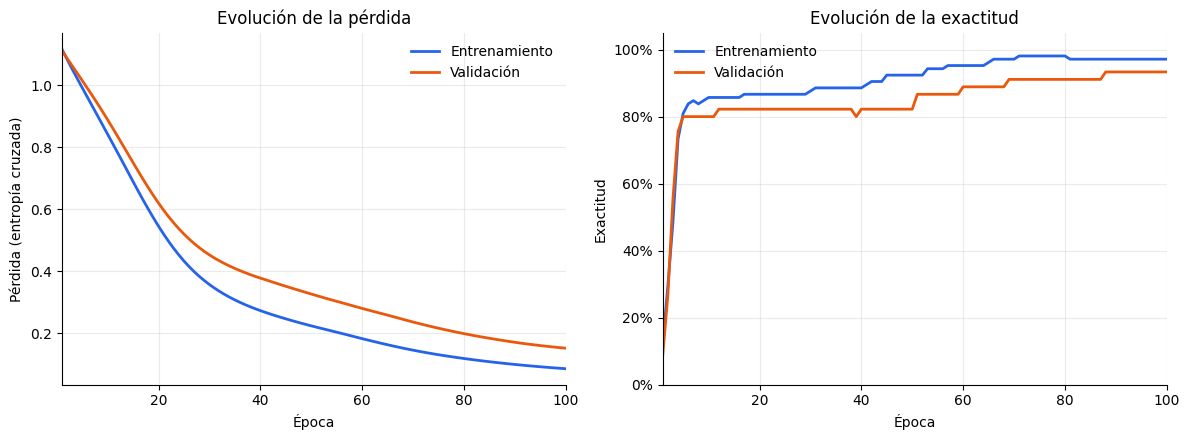

Pérdida de entrenamiento — primera época: 1.1173; última época: 0.0852
Pérdida de validación — primera época: 1.1130; última época: 0.1514
Exactitud final de entrenamiento: 97.14%
Exactitud final de validación: 93.33%


In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

epochs_range = range(1, len(history["train_loss"]) + 1)

#Establezco los colores que deseo para los gráficos.
TRAIN_COLOR = "#2563EB"
VAL_COLOR = "#EA580C"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

#Evolución de la pérdida.
axes[0].plot(
    epochs_range, history["train_loss"],
    label="Entrenamiento", color=TRAIN_COLOR, linewidth=2
)
axes[0].plot(
    epochs_range, history["val_loss"],
    label="Validación", color=VAL_COLOR, linewidth=2
)
axes[0].set_title("Evolución de la pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida (entropía cruzada)")

#Evolución de la exactitud.
axes[1].plot(
    epochs_range, history["train_accuracy"],
    label="Entrenamiento", color=TRAIN_COLOR, linewidth=2
)
axes[1].plot(
    epochs_range, history["val_accuracy"],
    label="Validación", color=VAL_COLOR, linewidth=2
)
axes[1].set_title("Evolución de la exactitud")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Exactitud")
axes[1].set_ylim(0, 1.05)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))

for ax in axes:
    ax.set_xlim(1, len(history["train_loss"]))
    ax.grid(True, alpha=0.25)
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

print(
    "Pérdida de entrenamiento — "
    f"primera época: {history['train_loss'][0]:.4f}; "
    f"última época: {history['train_loss'][-1]:.4f}"
)
print(
    "Pérdida de validación — "
    f"primera época: {history['val_loss'][0]:.4f}; "
    f"última época: {history['val_loss'][-1]:.4f}"
)
print(f"Exactitud final de entrenamiento: {history['train_accuracy'][-1]:.2%}")
print(f"Exactitud final de validación: {history['val_accuracy'][-1]:.2%}")

### Interpretación de los resultados

Durante las 100 épocas, la pérdida de entrenamiento disminuyó de
1.1173 a 0.0852 y la de validación de 1.1130 a 0.1514.

La exactitud final fue del 97,14 % en entrenamiento y del 93,33 %
en validación, equivalente a 42 clasificaciones correctas sobre
45 registros de validación.

Ambas curvas de pérdida descendieron y no se observó un aumento
sostenido de la pérdida de validación. En esta ejecución no aparecen
señales claras de sobreajuste marcado.

Los resultados corresponden a una única partición de un dataset
pequeño y deben interpretarse dentro de ese alcance.

In [7]:
from importlib.metadata import version

#Dependencias externas utilizadas en el notebook.
for package in ["numpy", "pandas", "scikit-learn", "matplotlib", "torch"]:
    print(f"{package}=={version(package)}")

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
torch==2.11.0+cpu
